# Aula 04 — Laboratório NumPy e Pandas I · Conteúdo

**Unidade 1 — Introdução à Ciência de Dados e Python** · ver também: [exercícios](exercicios.ipynb) · [atividades](atividades.ipynb)

## 📊 Aula 04 — Laboratório NumPy e Pandas I

**(Prática)** Quarta aula da Unidade 1. Criação e manipulação de DataFrames; seleção e filtragem (`loc`/`iloc`); leitura de CSV/Excel; inspeção básica (`head`, `info`, `describe`); atribuição segura e tratamento de valores ausentes.

**Recursos:** Jupyter Notebook, conjuntos de dados de exemplo (matrículas do IFRN — dados sintéticos).  
**Avaliação:** exercício prático entregue no Moodle + formulário avaliativo com 10 questões.

*Materiais desta aula:* livro *Tópicos de Estudo* (6 capítulos) · apostila completa em PDF (31 páginas) · pacote com o notebook e os dados · exemplo prático comentado · tarefa de entrega · formulário avaliativo.

---
## Tópicos de Estudo — Aula 04: Laboratório NumPy e Pandas I

### Descrição

Conteúdo teórico da Aula 04 em formato de livro, em 6 capítulos: da lista Python ao DataFrame; anatomia de `Series` e `DataFrame`; criação de DataFrames e leitura de CSV/Excel; inspeção básica (`head`, `info`, `describe`); seleção com `loc` e `iloc`; filtragem booleana, atribuição segura e valores ausentes.

Leia com o Jupyter aberto: execute cada trecho, altere um parâmetro e observe o que muda. A apostila em PDF traz o mesmo conteúdo ampliado, com o laboratório guiado e o exercício.

### 1. Capítulo 1 — Do array ao DataFrame

Na Aula 03 representamos uma pequena tabela como uma **lista de dicionários**. Funciona — mas tente responder, em Python puro, a pergunta *"qual a nota média dos estudantes do turno noturno, por campus, ignorando quem está sem nota?"*. O código tem três laços aninhados, um dicionário acumulador e várias verificações de `None`. Em Pandas, a mesma pergunta cabe em uma linha.

#### Três camadas empilhadas

- **Python puro** (`list`, `dict`): flexibilidade total, mas cada elemento é um objeto separado na memória e toda operação exige laço explícito.
- **NumPy** (`ndarray`): bloco contíguo de memória, um único tipo, operações vetorizadas executadas em C. Em compensação: um só tipo por array, sem nomes de coluna, sem suporte nativo a ausentes em inteiros.
- **Pandas** (`Series`, `DataFrame`): colunas *nomeadas* e de *tipos diferentes*, índice rotulado, alinhamento automático, tratamento de ausentes e leitura de dezenas de formatos — ao custo de mais memória e alguma sobrecarga.

A frase que vale guardar: **Pandas é NumPy com rótulos, tipos mistos e tratamento de dados faltantes.** Quase tudo o que confunde em Pandas — o índice, o `NaN`, o `dtype object`, o `SettingWithCopyWarning` — aparece exatamente onde essas três adições encostam no NumPy de baixo.

#### Vetorização

Vetorizar é aplicar uma operação a todos os elementos de uma vez. O laço continua existindo; apenas passou a rodar em código compilado.

In [ ]:
# Python puro: o laço está no seu código, interpretado
bonus = []
for n in lista_notas:
    bonus.append(n * 1.05)

# NumPy: o laço está dentro da biblioteca, compilado
bonus = notas * 1.05

Para arrays grandes, a segunda forma é tipicamente 10 a 100 vezes mais rápida. Regra prática: *se você escreveu um `for` percorrendo linhas de um DataFrame, quase certamente existe uma forma vetorizada melhor.*

#### Indexação booleana: o mecanismo por trás de toda filtragem

In [ ]:
import numpy as np
notas = np.array([72.5, 68.0, 91.3, 55.4, 80.1])

notas >= 70            # array([ True, False,  True, False,  True])
notas[notas >= 70]     # array([72.5, 91.3, 80.1])
(notas >= 70).sum()    # 3   -> True vale 1, False vale 0
(notas >= 70).mean()   # 0.6 -> proporção de aprovados

Como `True == 1`, `mascara.sum()` conta os casos e `mascara.mean()` devolve a *proporção*. Você usará isso o tempo todo para calcular taxas.

#### Ausentes em NumPy e em Pandas

Em NumPy, `np.mean` de um array com `NaN` devolve `NaN`; é preciso usar `np.nanmean`. Em Pandas, `.mean()` já ignora ausentes **por padrão**. É conveniente e perigoso: uma média calculada sobre 441 de 482 estudantes não é a média da turma, e o Pandas não avisa.

### 2. Capítulo 2 — Series, DataFrame e o índice

#### Series: um vetor com rótulos

Uma `Series` é um array unidimensional acompanhado de um **índice** (os rótulos das posições) e de um **nome**.

In [ ]:
import pandas as pd

s = pd.Series([72.5, 68.0, 91.3],
              index=["20261000", "20261001", "20261002"],
              name="nota_final")

s.values   # array([72.5, 68. , 91.3])  -> o ndarray NumPy por baixo
s.index    # Index(['20261000', '20261001', '20261002'], dtype='object')
s.dtype    # dtype('float64')

#### Alinhamento automático

O índice não é decoração: ele governa a combinação entre objetos. Ao operar duas Series, o Pandas casa os **rótulos**, não as posições.

In [ ]:
a = pd.Series([10, 20, 30], index=["x", "y", "z"])
b = pd.Series([ 1,  2,  3], index=["z", "y", "x"])   # ordem invertida

a + b
# x    13    <- 10 + 3, casado pelo rótulo "x"
# y    22
# z    31

**Consequência prática:** somar colunas vindas de DataFrames com índices diferentes pode produzir `NaN` — não porque os dados estejam errados, mas porque os rótulos não casaram. Ao concatenar ou reordenar, use `.reset_index(drop=True)`.

#### DataFrame: um dicionário ordenado de Series

Um `DataFrame` é uma tabela bidimensional: várias Series que **compartilham o mesmo índice**.

- `df.shape` — tupla (linhas, colunas)
- `df.columns` / `df.index` — rótulos de colunas e de linhas
- `df.dtypes` — tipo de cada coluna
- `df.to_numpy()` — o conteúdo como array NumPy
- `len(df)` — número de **linhas**

#### Os dtypes que você vai encontrar

- `int64` — inteiros. **Não aceita `NaN`**: um único ausente converte a coluna inteira para `float64`.
- `float64` — decimais; tipo padrão de coluna numérica com ausentes.
- `object` / `str` — texto e tipos mistos. Frequentemente sinaliza número lido como texto.
- `bool` — resultado de toda comparação.
- `datetime64[ns]` — datas; só aparece com `parse_dates=` ou `pd.to_datetime()`.
- `category` — texto com poucos valores distintos; economiza muita memória em colunas como `turno` ou `campus`.

**Sintoma mais comum de leitura malfeita:** uma coluna que deveria ser numérica aparece como `object`. Causas quase sempre: vírgula decimal não declarada, separador de milhar, ou um texto como `"N/D"` no meio dos números.

### 3. Capítulo 3 — Criando DataFrames e lendo arquivos

#### Cinco formas de criar um DataFrame

In [ ]:
# (a) dicionário de listas — as chaves viram colunas
df = pd.DataFrame({"campus": ["Natal-Central", "Mossoró"],
                   "alunos": [98, 70]})

# (b) lista de dicionários — um registro por linha; chave ausente vira NaN
df = pd.DataFrame([{"campus": "Natal-Central", "alunos": 98},
                   {"campus": "Mossoró"}])

# (c) lista de tuplas + columns
df = pd.DataFrame([("Natal-Central", 98), ("Mossoró", 70)],
                  columns=["campus", "alunos"])

# (d) array NumPy — quando tudo é numérico
df = pd.DataFrame(np.zeros((5, 3)), columns=["p1", "p2", "p3"])

# (e) com índice significativo
df = df.set_index("campus")     # promove coluna a índice
df = df.reset_index()           # desfaz

#### read_csv: os parâmetros que importam

O CSV é apenas texto, sem esquema, e cada sistema o gera à sua maneira. **Ler um CSV brasileiro com os parâmetros padrão quase sempre dá errado**, porque o padrão do Pandas é o formato norte-americano.

- `sep=";"` — separador de campos
- `decimal=","` — separador decimal
- `thousands="."` — separador de milhar
- `encoding="utf-8"` / `"latin-1"` / `"cp1252"`
- `dtype={"matricula": "string"}` — força o tipo de colunas específicas
- `usecols=[...]` e `nrows=1000` — lê só o necessário
- `na_values=["N/D", "-"]` — textos a tratar como ausente
- `parse_dates=["data"]` — converte para `datetime64`
- `index_col="matricula"`, `skiprows=3`

In [ ]:
df = pd.read_csv("dados/matriculas_ifrn_2026.csv",
                 sep=";", decimal=",", encoding="utf-8",
                 dtype={"matricula": "string"})

#### Por que a matrícula não pode ser inteiro

Identificadores lidos como `int64` perdem zeros à esquerda (`"00123"` vira `123`), estouram a precisão em códigos longos e passam a aceitar operações sem sentido, como somar duas matrículas. **Regra: se não faz sentido calcular a média, não é número — é texto.** Vale para CPF, CEP, SIAPE e código de escola.

#### Diagnóstico rápido

Antes de insistir em parâmetros, olhe o arquivo cru — as três primeiras linhas revelam quase tudo. Acentos corrompidos (`MossorÃ³`) indicam codificação errada; uma única coluna gigante indica `sep` errado.

In [ ]:
with open("dados/matriculas_ifrn_2026.csv", encoding="utf-8") as f:
    for _ in range(3):
        print(f.readline().rstrip())

#### read_excel

Requer `openpyxl` para arquivos `.xlsx`. A diferença em relação ao CSV é a existência de **planilhas (abas)**.

In [ ]:
campi  = pd.read_excel("dados/campi_ifrn.xlsx", sheet_name="campi")
todas  = pd.read_excel("dados/campi_ifrn.xlsx", sheet_name=None)  # dict
df     = pd.read_excel("relatorio.xlsx", skiprows=4)  # pula título decorativo

Planilhas costumam trazer células mescladas, títulos decorativos e totais no meio da tabela. Sempre confira `df.head()` e `df.dtypes` logo após ler um `.xlsx`.

#### Gravando

`df.to_csv("saida.csv", index=False)` — sem `index=False`, o índice vira uma coluna anônima que reaparece como `Unnamed: 0` na próxima leitura.

### 4. Capítulo 4 — Inspeção básica: as sete primeiras perguntas

Diante de um arquivo desconhecido, esta sequência deve ser **automática**. Leva menos de um minuto e evita horas de análise sobre dados quebrados.

1.  `df.shape` — quantas linhas e colunas? O número bate com o esperado?
2.  `df.head()` / `df.sample(5)` — com o que esses dados se parecem?
3.  `df.info()` — que tipo tem cada coluna? Quantos não nulos?
4.  `df.describe()` — as estatísticas fazem sentido?
5.  `df.isna().sum()` — onde estão os buracos?
6.  `df["col"].value_counts()` — que categorias existem?
7.  `df.duplicated().sum()` — há linhas repetidas?

#### Lendo o info()

É a saída mais informativa do Pandas. Três colunas importam:

- **Non-Null Count** — comparado ao total de linhas, revela imediatamente quantos ausentes cada coluna tem. Se `RangeIndex` mostra 482 e a coluna mostra 441, são 41 ausentes.
- **Dtype** — coluna que deveria ser numérica aparecendo como `object` significa que a leitura precisa ser corrigida *antes* de qualquer análise.
- **memory usage** — use `df.info(memory_usage="deep")` para o tamanho real das colunas de texto.

#### Lendo o describe()

Por padrão resume apenas colunas numéricas: `count`, `mean`, `std`, `min`, `25%`, `50%` (mediana), `75%`, `max`.

- **`count` menor que `len(df)`** denuncia ausentes naquela coluna — e lembra que a média exibida foi calculada só sobre os presentes.
- **Média muito distante da mediana** sugere assimetria ou valores extremos.
- **`min` ou `max` impossíveis** (idade 0, nota 999) indicam erro de coleta ou código de ausência disfarçado de número.
- `df.describe(include="all")` inclui as colunas de texto, com `unique`, `top` e `freq`.

*Nota de versão:* a partir do Pandas 3.0 as colunas de texto têm dtype próprio `str`, e `describe(include="object")` emite aviso de compatibilidade. Prefira `include="all"`. Verifique sua versão com `pd.__version__`.

#### value_counts(): o detector de sujeira

In [ ]:
df["turno"].value_counts()                  # contagem absoluta
df["turno"].value_counts(normalize=True)    # proporção
df["turno"].value_counts(dropna=False)      # inclui os NaN
df["campus"].nunique()                      # quantos distintos

É a ferramenta número um para detectar categorias sujas: `"Natal-Central"`, `"natal-central"` e `" Natal-Central "` aparecem como três valores diferentes. No conjunto desta aula, `nunique()` devolve **19** campi antes da limpeza e **12** depois de `str.strip()`.

### 5. Capítulo 5 — Seleção com loc e iloc

Este é o ponto em que a maioria dos iniciantes escorrega. A confusão desaparece com uma única distinção:

> **`loc` trabalha com RÓTULOS** (o que está escrito no índice e nos nomes das colunas).  
> **`iloc` trabalha com POSIÇÕES** (inteiros de 0 a n−1, como em listas Python).

#### Colchetes simples

In [ ]:
df["nota_final"]              # uma COLUNA -> Series
df[["nome", "nota_final"]]    # várias colunas -> DataFrame
df[0:5]                       # fatia de LINHAS por posição (ambíguo!)
df[df["nota_final"] > 90]     # filtragem booleana de LINHAS

Note a ambiguidade: com um texto, `[]` seleciona coluna; com fatia ou máscara, seleciona linhas. Por isso, **para qualquer seleção que não seja "uma ou mais colunas inteiras", prefira `loc` ou `iloc`**.

#### loc — por rótulo

In [ ]:
df.loc[0]                                 # linha de RÓTULO 0
df.loc[0, "nome"]                         # uma célula
df.loc[0:2]                               # rótulos 0, 1 E 2 -> fim INCLUÍDO
df.loc[0:2, ["nome", "campus"]]           # linhas x colunas
df.loc[df["turno"] == "Noturno", "nota_final"]   # filtro + coluna

#### iloc — por posição

In [ ]:
df.iloc[0]                    # PRIMEIRA linha, seja qual for o rótulo
df.iloc[0, 1]                 # 1ª linha, 2ª coluna
df.iloc[0:3]                  # posições 0, 1, 2 -> fim EXCLUÍDO
df.iloc[0:3, 0:4]             # 3 primeiras linhas, 4 primeiras colunas
df.iloc[-1]                   # última linha
df.iloc[[0, 5, 10], [1, 9]]   # listas de posições

#### A pegadinha clássica

Com o índice padrão, `df.loc[0:2]` devolve **três** linhas e `df.iloc[0:2]` devolve **duas**. Não é bug: `loc` fatia rótulos (intervalo fechado), `iloc` fatia posições (intervalo semiaberto, como toda fatia Python).

#### Quando o índice deixa de ser 0, 1, 2…

In [ ]:
noturno = df[df["turno"] == "Noturno"]
noturno.index[:5]     # Index([0, 1, 5, 8, 10], ...) -> com buracos

noturno.loc[5]        # a linha cujo RÓTULO é 5
noturno.iloc[5]       # a 6ª linha deste subconjunto

noturno = noturno.reset_index(drop=True)   # renumera 0..n-1

Depois de `set_index("matricula")`, `dfm.loc["20261250"]` funciona e `dfm.iloc["20261250"]` falha: `iloc` exige um inteiro de posição, nunca um texto.

#### at e iat

Versões otimizadas para acessar **um único valor escalar**: `df.at[0, "nome"]` (rótulo) e `df.iat[0, 1]` (posição). Mais rápidas, porém mais restritas.

### 6. Capítulo 6 — Filtragem, atribuição segura e valores ausentes

#### Máscaras booleanas

Filtrar é selecionar linhas por uma *condição*. A condição produz uma Series de `True`/`False` do tamanho do DataFrame, usada como índice.

In [ ]:
mascara = df["nota_final"] >= 70
df[mascara]
df.loc[mascara, ["nome", "nota_final"]]   # filtra E escolhe colunas

#### Dois erros que todo iniciante comete

1.  **Usar `and`/`or` no lugar de `&`/`|`.** Os operadores do Python esperam um único booleano e disparam `ValueError: The truth value of a Series is ambiguous`.
2.  **Esquecer os parênteses.** `&` tem precedência maior que `>=`, então `df["a"] > 1 & df["b"] < 2` é avaliado na ordem errada.

In [ ]:
# CERTO
df[(df["turno"] == "Noturno") & (df["nota_final"] >= 80)]   # E
df[(df["campus"] == "Mossoró") | (df["campus"] == "Apodi")]  # OU
df[~(df["situacao"] == "Aprovado")]                          # NÃO

#### Atalhos que deixam o código legível

- `df["campus"].isin(lista)` — pertence a um conjunto; substitui uma cadeia de `|`
- `df["idade"].between(18, 24)` — intervalo fechado
- `df["curso"].str.contains("Sistemas|Redes", na=False)` — texto contém; aceita regex. **`na=False` não é opcional**: um ausente produziria `NaN` na máscara e levantaria erro.
- `df.query("turno == 'Noturno' and nota_final >= 80")` — filtro em string
- `df.nlargest(10, "nota_final")`, `df.sort_values("nota_final", ascending=False)`

#### Atribuição segura e o SettingWithCopyWarning

In [ ]:
# ERRADO — "indexação encadeada": dois colchetes em sequência
df[df["frequencia"].isna()]["frequencia"] = 85.0

# CERTO — uma única operação com loc: [linhas, coluna]
df.loc[df["frequencia"].isna(), "frequencia"] = 85.0

**Por quê?** `df[mascara]` pode devolver uma *cópia* ou uma *vista* — o Pandas não garante qual. Se for cópia, a atribuição altera um objeto temporário que será descartado. Com `df.loc[linhas, coluna] = valor` o Pandas sabe que a intenção é escrever no original. Ao derivar um subconjunto que será alterado, use `.copy()` explicitamente.

#### A armadilha do np.where com ausentes

`NaN >= 70` é `False`. Logo, `np.where(df["nota"] >= 70, "Bom", "A melhorar")` classifica silenciosamente todos os estudantes *sem nota* como "A melhorar". A correção é reinserir o ausente depois:

In [ ]:
df["faixa"] = df["faixa"].mask(df["nota_final"].isna())

#### NaN não é zero

Ausente significa "não sei", e isso é diferente de "zero" e de "vazio".

- `df.isna().sum()` — quantos ausentes por coluna
- `df.isna().mean()` — *proporção* de ausentes
- `df.dropna(subset=["nota_final"])` — remove só quem falta naquela coluna
- `df["col"].fillna(df["col"].median())` — imputa pela mediana

A pergunta certa não é "como remover os `NaN`?", e sim **"por que eles estão ali?"**. No conjunto desta aula, os 41 estudantes sem `nota_final` estão em situação *Trancado* (27) ou *Em curso* (14): a nota não existe ainda — não foi perdida. Preenchê-la com a média criaria desempenho fictício. Já a `frequencia` ausente em 9 registros é plausivelmente falha de registro, e imputar a mediana é defensável — **desde que a decisão seja documentada**.

#### O que vem na Aula 05

*Laboratório Pandas II — Agrupamentos e Joins*: `groupby`, `agg`, `pivot_table`, `merge`/`join`, `apply` com `lambda` e *method chaining*.

---
## Conteúdo — Aula 04: Laboratório NumPy e Pandas I (apostila em PDF)

> Convertido de [`Aula04_NumPy_Pandas_I.pdf`](Aula04_NumPy_Pandas_I.pdf) (o original está nesta pasta — confira nele figuras e diagramação).

INSTITUTO FEDERAL DE EDUCAÇÃO, CIÊNCIA E TECNOLOGIA DO RIO GRANDE DO NORTE ESPECIALIZAÇÃO EM CIÊNCIA DE DADOS  ·  DISCIPLINA: ANÁLISE E CIÊNCIA DE DADOS

### Aula 04 - Laboratório NumPy e Pandas I

Criação e manipulação de DataFrames, seleção e filtragem, leitura de CSV/Excel e inspeção básica

Unidade

Natureza Unidade 1 - Introdução à Ciência de Dados e Python (Aulas 01-05)

Aula prática (laboratório)

Carga horária

4 h/a - 1 h de exposição guiada + 3 h de laboratório

Pré-

requisitos

Recursos Aula 03 - ambiente Python instalado, Jupyter funcionando, noções de listas, dicionários, funções e arrays NumPy Jupyter Notebook/Lab, pandas , numpy , openpyxl , conjuntos de dados de exemplo

Avaliação Exercício prático entregue no Moodle + formulário avaliativo (10 questões)

Professor Plácido Antônio de Souza Neto

### Objetivos de aprendizagem

Ao final desta aula, espera-se que o estudante seja capaz de:

1. Explicar a relação entre o ndarray do NumPy e as estruturas Series e DataFrame do Pandas, identificando o que cada camada acrescenta.
2. Criar DataFrames a partir de dicionários, listas de dicionários, listas de tuplas e arrays NumPy, escolhendo a forma adequada a cada situação.
3. Ler arquivos CSV e Excel do mundo real, ajustando separador, separador decimal, codificação, tipos de coluna e marcadores de valor ausente.
4. Inspecionar um conjunto de dados desconhecido com shape , head , info , describe , isna e value\_counts , e relatar o que foi encontrado.
5. Selecionar linhas e colunas com loc e iloc , distinguindo com segurança seleção por rótulo e por posição.
6. Filtrar dados com máscaras booleanas compostas, isin , between , str.contains e query .
7. Atribuir valores de forma segura, reconhecendo e evitando o SettingWithCopyWarning .
8. Interpretar o resultado de uma análise inicial e apontar suas limitações.

### Sumário

### Parte I - Fundamentos teóricos

- 1.1 Por que Pandas existe: da lista ao DataFrame
- 1.2 NumPy: o alicerce numérico
- 1.3 Anatomia da Series e do DataFrame

- 1.4 Criando DataFrames: cinco caminhos
- 1.5 Lendo arquivos: CSV, Excel e outros formatos
- 1.6 Inspeção básica: as primeiras sete perguntas
- 1.7 Seleção: [] , loc , iloc , at , iat
- 1.8 Filtragem com máscaras booleanas
- 1.9 Atribuição segura e o SettingWithCopyWarning
- 1.10 Valores ausentes: NaN não é zero
- 1.11 Erros mais comuns e como corrigi-los
- 1.12 Boas práticas de laboratório

Parte II - Tópicos de estudo dirigido (roteiro de leitura)

Parte III - Laboratório guiado: matrículas do IFRN

Parte IV - Exercício prático avaliativo (entrega no Moodle)

Parte V - Formulário avaliativo (10 questões)

Apêndice A - Colinha de comandos

Apêndice B - Referências e leituras recomendadas

### SOBRE OS DADOS USADOS NESTA AULA

Todos os exemplos usam um conjunto de dados sintético ( matriculas\_ifrn\_2026.csv e campi\_ifrn.xlsx ). Os nomes de campi e cursos são reais; matrículas, nomes de estudantes, notas, frequências e situações foram gerados aleatoriamente com semente fixa. Nenhuma conclusão sobre o IFRN pode ser extraída desses números. A escolha por dados sintéticos é deliberada: ela permite inserir, de propósito, os defeitos que aparecem em dados reais - valores ausentes, espaços sobrando, linhas duplicadas e tipos mal inferidos - sem expor informação de nenhuma pessoa.

### Parte I - Fundamentos teóricos

Conceitos necessários para entender o que o código faz, e não apenas repeti-lo

### 1.1 Por que Pandas existe: da lista ao DataFrame

Na Aula 03 representamos uma pequena tabela como uma lista de dicionários . Funciona, e é instrutivo - mas experimente responder, com Python puro, a pergunta "qual a nota média dos estudantes do turno noturno, por campus, ignorando quem está sem nota?" . O código resultante tem três laços aninhados, um dicionário acumulador e várias verificações de None . Em Pandas, a mesma pergunta cabe em uma linha.

A diferença não é apenas de digitação. É de nível de abstração . Existem três camadas empilhadas, e é importante saber em qual delas se está trabalhando:

| Camada | O que oferece | Limitação |
|---------------------------|-------------------------------------------------------------------------------------------------------------------------------------------|---------------------------------------------------------------------------------------------|
| Python puro list , dict | Flexibilidade total; qualquer tipo em qualquer posição. | Lento: cada elemento é um objeto separado na memória. Toda operação exige laço explícito. |
| NumPy ndarray | Bloco contíguo de memória, tipo único, operações vetorizadas em C. | Um só tipo por array; sem nomes de coluna; sem suporte nativo a dados ausentes em inteiros. |
| Pandas Series , DataFrame | Colunas nomeadas e de tipos diferentes , índice rotulado, alinhamento automático, tratamento de ausentes, leitura de dezenas de formatos. | Mais memória e alguma sobrecarga; ainda é preciso entender a camada NumPy por baixo. |

A frase que vale a pena guardar: Pandas é NumPy com rótulos, tipos mistos e tratamento de dados faltantes. Quase tudo o que causa confusão em Pandas - o índice, o NaN , o dtype object , o SettingWithCopyWarning - aparece exatamente nos pontos em que essas três adições encostam no NumPy de baixo.

### O ciclo de trabalho desta aula

Toda análise de dados começa com os mesmos cinco movimentos, na mesma ordem. Esta aula cobre os quatro primeiros; a Aula 05 avança sobre o quinto.

| # | Movimento | Pergunta que responde | Ferramentas |
|-----|-------------|------------------------------------------------|---------------------------------------|
| 1 | Ler | Consigo carregar o arquivo corretamente ? | read_csv , read_excel |
| 2 | Inspecionar | O que existe aqui dentro? O que está quebrado? | shape , head , info , describe , isna |
| 3 | Selecionar | Quais linhas e colunas me interessam? | [] , loc , iloc |
| 4 | Filtrar | Qual subconjunto responde à minha pergunta? | máscaras booleanas, isin , query |
| 5 | Resumir | O que os dados dizem? | groupby , agg , pivot_table (Aula 05) |

### 1.2 NumPy: o alicerce numérico

Pandas guarda os dados de cada coluna em arrays NumPy. Entender o array explica o comportamento do DataFrame.

### O ndarray e o dtype

Um array NumPy é um bloco contíguo de memória com um único tipo ( dtype ) e uma forma ( shape ). É essa uniformidade que permite ao NumPy delegar o cálculo para código compilado em C.

In [ ]:
import numpy as np

notas = np.array([72.5, 68.0, 91.3, 55.4, 80.1])

notas.dtype     # dtype('float64')  -> todos os elementos são float de 64 bits
notas.shape     # (5,)              -> vetor de 5 posições, 1 dimensão
notas.ndim      # 1
notas.size      # 5
notas.nbytes    # 40  -> 5 elementos x 8 bytes

### Vetorização

Vetorizar é aplicar uma operação a todos os elementos de uma vez, sem escrever o laço em Python. O laço continua existindo - apenas passou a rodar em C.

In [ ]:
# Python puro: o laço está no seu código, interpretado
bonus = []
for n in lista_notas:
    bonus.append(n * 1.05)

# NumPy: o laço está dentro da biblioteca, compilado
bonus = notas * 1.05

Além de mais curto, o segundo é tipicamente 10 a 100 vezes mais rápido para arrays grandes. A regra prática em análise de dados é direta: se você escreveu um for percorrendo linhas de um DataFrame, quase certamente existe uma forma vetorizada melhor.

### Broadcasting

Quando os operandos têm formas diferentes, o NumPy "estica" o menor até casar com o maior, sem copiar dados. É por isso que notas * 1.05 funciona: o escalar 1.05 é difundido sobre os cinco elementos.

In [ ]:
pesos  = np.array([0.4, 0.6])                 # shape (2,)
provas = np.array([[70., 80.],
                   [90., 65.],
                   [50., 75.]])               # shape (3, 2)

media_ponderada = (provas * pesos).sum(axis=1)
# array([76., 75., 65.])  -> o vetor de pesos foi aplicado a cada linha

### Indexação booleana

Este é o mecanismo que sustenta toda a filtragem em Pandas. Uma comparação sobre um array produz outro array, de dtype bool , do mesmo tamanho - a máscara . Usar a máscara como índice devolve apenas as posições True .

In [ ]:
notas >= 70            # array([ True, False,  True, False,  True])
notas[notas >= 70]     # array([72.5, 91.3, 80.1])
(notas >= 70).sum()    # 3   -> True vale 1, False vale 0
(notas >= 70).mean()   # 0.6 -> proporção de aprovados

### TRUQUE ÚTIL

Como True == 1 , mascara.sum() conta quantos casos satisfazem a condição e mascara.mean() devolve a proporção deles. Você usará isso o tempo todo para calcular taxas (de aprovação, de evasão, de valores ausentes).

### Funções que ignoram ausentes

O NaN ( Not a Number ) contamina qualquer cálculo comum: np.mean de um array com NaN devolve NaN . As variantes com prefixo nan ignoram esses valores.

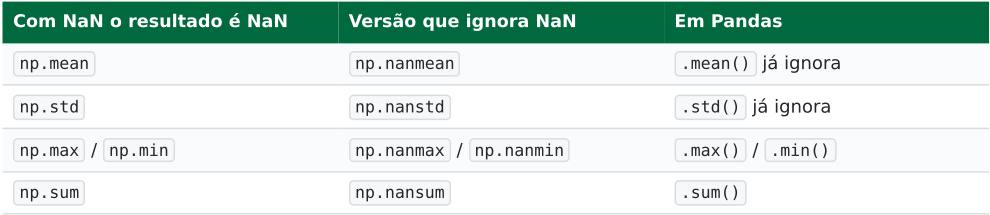

Diferença importante: em NumPy, ignorar ausentes é opcional e explícito; em Pandas, é o comportamento padrão . Isso é conveniente, mas perigoso: uma média calculada sobre 441 de 482 estudantes não é a média da turma, e o Pandas não avisa.

### 1.3 Anatomia da Series e do DataFrame

### Series: um vetor com rótulos

Uma Series é um array unidimensional acompanhado de um índice (os rótulos das posições) e de um nome .

In [ ]:
import pandas as pd

s = pd.Series([72.5, 68.0, 91.3],
              index=["20261000", "20261001", "20261002"],
              name="nota_final")

s.values    # array([72.5, 68. , 91.3])  -> o ndarray NumPy por baixo
s.index     # Index(['20261000', '20261001', '20261002'], dtype='object')
s.name      # 'nota_final'
s.dtype     # dtype('float64')

O índice não é decoração. Ele governa o alinhamento automático : quando duas Series são combinadas, o Pandas casa os rótulos, não as posições.

In [ ]:
a = pd.Series([10, 20, 30], index=["x", "y", "z"])
b = pd.Series([ 1,  2,  3], index=["z", "y", "x"])   # ordem invertida!

a + b
# x    13    <- 10 + 3, casado pelo rótulo "x", não pela posição
# y    22
# z    31

### CONSEQUÊNCIA PRÁTICA

Se você somar duas colunas vindas de DataFrames com índices diferentes, o resultado pode vir cheio de NaN - não porque os dados estejam errados, mas porque os rótulos não casaram. Ao concatenar ou reordenar DataFrames, use .reset\_index(drop=True) para reconstruir um índice limpo.

### DataFrame: um dicionário ordenado de Series

Um DataFrame é uma tabela bidimensional: várias Series que compartilham o mesmo índice . A forma mais precisa de imaginá-lo é "um dicionário ordenado cujas chaves são os nomes das colunas e cujos valores são Series".

| Atributo | O que devolve |
|------------|------------------------------------------------------------|
| df.shape | Tupla (linhas, colunas) |
| df.columns | Index com os nomes das colunas |
| df.index | Index com os rótulos das linhas |
| df.dtypes | Series com o tipo de cada coluna |
| df.values | O conteúdo como array NumPy (com tipos mistos, vira object |
| df.size | Número total de células ( linhas × colunas ) |
| len(df) | Número de linhas |

### Os tipos ( dtypes ) que você vai encontrar

| dtype | Guarda | Observação |
|----------------|------------------------------------|----------------------------------------------------------------------------|
| int64 | Inteiros | Não aceita NaN ; um único ausente converte a coluna inteira para float64 . |
| float64 | Decimais | Tipo padrão de qualquer coluna numérica com ausentes. |
| object / str | Texto e tipos mistos | Lento e vago; frequentemente sinaliza número lido como texto. |
| bool | True / False | Resultado de toda comparação. |
| datetime64[ns] | Datas e horas | Só aparece com parse_dates= ou pd.to_datetime() . |
| category | Texto com poucos valores distintos | Economiza muita memória em colunas como turno ou campus . |

### O SINTOMA MAIS COMUM DE LEITURA MALFEITA

Uma coluna que deveria ser numérica aparece como object em df.dtypes . Causas quase sempre: vírgula decimal não declarada ( decimal="," ), separador de milhar ( thousands="." ), ou um texto como "N/D" no meio dos números ( na\_values=["N/D"] ).

### 1.4 Criando DataFrames: cinco caminhos

Na prática profissional você quase sempre lê um arquivo. Mas saber construir um DataFrame à mão é essencial para testar hipóteses, montar exemplos mínimos e escrever testes.

### (a) Dicionário de listas - o mais usado

As chaves viram colunas. Todas as listas precisam ter o mesmo comprimento.

In [ ]:
df = pd.DataFrame({
    "campus": ["Natal-Central", "Mossoró", "Caicó"],
    "alunos": [96, 52, 31],
    "nota":   [68.1, 71.7, 70.0],
})

### (b) Lista de dicionários - um registro por linha

Formato natural de quem vem de JSON ou de uma API. Chaves ausentes viram NaN .

In [ ]:
registros = [
    {"campus": "Natal-Central", "alunos": 96, "nota": 68.1},
    {"campus": "Mossoró",       "alunos": 52},              # sem "nota" -> NaN
]
df = pd.DataFrame(registros)

### (c) Lista de tuplas + columns

In [ ]:
linhas = [("Natal-Central", 96, 68.1), ("Mossoró", 52, 71.7)]
df = pd.DataFrame(linhas, columns=["campus", "alunos", "nota"])

### (d) Array NumPy - quando tudo é numérico

In [ ]:
matriz = np.random.default_rng(42).normal(70, 10, size=(5, 3)).round(1)
df = pd.DataFrame(matriz, columns=["prova1", "prova2", "prova3"])

### (e) Com índice significativo

Sempre que houver um identificador natural (matrícula, CPF, código do campus), vale promovê-lo a índice - a seleção com loc fica muito mais legível.

In [ ]:
df = pd.DataFrame(
    {"nota": [68.1, 71.7]},
    index=pd.Index(["20261000", "20261001"], name="matricula"),
)
# ou, a partir de uma coluna existente:
df = df.set_index("matricula")
df = df.reset_index()          # desfaz, devolvendo a coluna

### 1.5 Lendo arquivos: CSV, Excel e outros formatos

### read\_csv - os parâmetros que realmente importam

O CSV é o formato mais comum e o mais traiçoeiro: é apenas texto, sem esquema, e cada sistema o gera à sua maneira. Ler um CSV brasileiro com os parâmetros padrão quase sempre dá errado , porque o padrão do Pandas é o formato norte-americano (vírgula separando campos, ponto decimal).

| Parâmetro | Para que serve | Exemplo |
|-------------|-------------------------------------|--------------------------------------------|
| sep | Separador de campos | sep=";" (padrão brasileiro) |
| decimal | Separador decimal | decimal="," |
| thousands | Separador de milhar | thousands="." |
| encoding | Codificação do texto | "utf-8" , "latin-1" , "cp1252" |
| dtype | Força o tipo de colunas específicas | dtype={"matricula": "string"} |
| usecols | Lê só as colunas necessárias | usecols=["nome","nota_final"] |
| nrows | Lê só as N primeiras linhas | nrows=1000 (para espiar um arquivo enorme) |
| na_values | Textos a tratar como ausente | na_values=["N/D", "-", "sem informação"] |
| parse_dates | Converte colunas para data | parse_dates=["data_matricula"] |
| index_col | Usa uma coluna como índice | index_col="matricula" |
| skiprows | Pula linhas de cabeçalho sujo | skiprows=3 |

In [ ]:
df = pd.read_csv(
    "dados/matriculas_ifrn_2026.csv",
    sep=";",                          # campos separados por ponto e vírgula
    decimal=",",                      # 72,5 é um número, não texto
    encoding="utf-8",
    dtype={"matricula": "string"},    # identificador NÃO é número
)

### POR QUE A MATRÍCULA NÃO PODE SER INTEIRO

Identificadores lidos como int64 perdem zeros à esquerda ( "00123" vira 123 ), estouram a precisão em códigos muito longos e passam a aceitar operações sem sentido, como somar duas matrículas. Regra: se não faz sentido calcular a média, não é número - é texto. Vale para CPF, CEP , código de escola, número de processo e SIAPE.

### Descobrindo a codificação e o separador

Antes de insistir em parâmetros, olhe o arquivo cru. As três primeiras linhas revelam quase tudo:

```
# No terminal
head -3 dados/matriculas_ifrn_2026.csv

# Ou em Python, sem carregar o arquivo inteiro
with open("dados/matriculas_ifrn_2026.csv", encoding="utf-8") as f:
    for _ in range(3):
        print(f.readline().rstrip())
```

Se aparecerem caracteres estranhos no lugar dos acentos ( MossorÃ³ ), a codificação declarada está errada - tente latin-1 ou cp1252 . Se o Pandas devolver uma única coluna gigante, o sep está errado.

### read\_excel

Requer o pacote openpyxl para arquivos .xlsx ( pip install openpyxl ). A grande diferença em relação ao CSV é a existência de planilhas (abas) .

In [ ]:
campi  = pd.read_excel("dados/campi_ifrn.xlsx", sheet_name="campi")
cursos = pd.read_excel("dados/campi_ifrn.xlsx", sheet_name="cursos")

# sheet_name=None devolve um DICIONÁRIO {nome_da_aba: DataFrame}
todas = pd.read_excel("dados/campi_ifrn.xlsx", sheet_name=None)
todas.keys()        # dict_keys(['campi', 'cursos'])

# Planilha com título nas primeiras linhas:
df = pd.read_excel("relatorio.xlsx", sheet_name=0, skiprows=4, header=0)

### EXCEL NÃO É UM FORMATO DE DADOS

Planilhas costumam trazer células mescladas, títulos decorativos, totais no meio da tabela e colunas com formatação que engana o Pandas. Sempre confira df.head() e df.dtypes logo após ler um .xlsx .

### Outros formatos e a escrita

| Formato | Leitura | Escrita |
|-----------|-------------------|------------------------------------|
| CSV | pd.read_csv() | df.to_csv("x.csv", index=False) |
| Excel | pd.read_excel() | df.to_excel("x.xlsx", index=False) |
| JSON | pd.read_json() | df.to_json() |
| Parquet | pd.read_parquet() | df.to_parquet() |
| Banco SQL | pd.read_sql() | df.to_sql() |
| HTML | pd.read_html(url) | df.to_html() |

Ao gravar CSV, lembre-se de index=False - caso contrário o índice vira uma coluna anônima extra, que reaparece como Unnamed: 0 na próxima leitura.

### 1.6 Inspeção básica: as primeiras sete perguntas

Diante de um arquivo desconhecido, a sequência abaixo deve ser automática . Ela leva menos de um minuto e evita horas de análise sobre dados quebrados.

| # | Comando | Pergunta que responde |
|-----|------------------------------------|-----------------------------------------------------------------|
| 1 | df.shape | Quantas linhas e colunas? O número bate com o esperado? |
| 2 | df.head() / df.tail() df.sample(5) | / Com o que esses dados se parecem? O cabeçalho foi lido certo? |
| 3 | df.info() | Que tipo tem cada coluna? Quantos não nulos? Quanta memória? |
| 4 | df.describe() | As estatísticas fazem sentido? Há mínimos ou máximos absurdos? |
| 5 | df.isna().sum() | Onde estão os buracos e qual o tamanho deles? |
| 6 | df["col"].value_counts() | Que categorias existem? Há grafias divergentes? |
| 7 | df.duplicated().sum() | Há linhas repetidas? |

### O que ler em cada saída

### head()

Mostra as 5 primeiras linhas ( head(10) para dez). Procure por: cabeçalho virado linha de dados, colunas deslocadas, números aparecendo com aspas, acentos corrompidos. sample(5) é frequentemente mais honesto: arquivos costumam ser ordenados, e as primeiras linhas podem não representar o conjunto.

### info()

A saída mais informativa do Pandas. Três colunas importam:

- Non-Null Count - comparando com o total de linhas, revela imediatamente quais colunas têm ausentes e quantos.
- Dtype - se uma coluna que deveria ser numérica está como object , a leitura precisa ser corrigida antes de qualquer análise.
- memory usage - use df.info(memory\_usage="deep") para o tamanho real das colunas de texto.

### describe()

Por padrão resume apenas as colunas numéricas, com oito estatísticas: count , mean , std , min , 25% , 50% (mediana), 75% e max .

- count menor que len(df) denuncia valores ausentes naquela coluna.
- Média muito distante da mediana sugere assimetria ou outliers .
- min ou max impossíveis (idade 0, nota 999, frequência negativa) indicam erro de coleta ou código de ausência disfarçado de número.
- df.describe(include="object") resume as colunas de texto com count , unique , top e freq . include="all" combina os dois.

### ATENÇÃO À VERSÃO

A partir do Pandas 3.0, colunas de texto passaram a ter o dtype dedicado str , e describe(include="object") emite um aviso de compatibilidade. Se você estiver no Pandas 3.x, prefira df.describe(include="all") . Verifique sua versão com pd.\_\_version\_\_ .

### value\_counts()

Conta as ocorrências de cada valor distinto de uma coluna. É a ferramenta número um para detectar sujeira em categorias: "Natal-Central" , "natal-central" e " Natal-Central " aparecem como três categorias diferentes.

In [ ]:
df["turno"].value_counts()                  # contagem absoluta
df["turno"].value_counts(normalize=True)    # proporção (0 a 1)
df["turno"].value_counts(dropna=False)      # inclui os NaN na contagem
df["campus"].nunique()                      # quantos valores distintos
df["campus"].unique()                       # quais são

### 1.7 Seleção: [] , loc , iloc , at , iat

Este é o ponto em que a maioria dos iniciantes escorrega. A confusão desaparece com uma única distinção:

### A REGRA QUE RESOLVE TUDO

loc trabalha com RÓTULOS (o que está escrito no índice e nos nomes das colunas). iloc trabalha com POSIÇÕES (números inteiros de 0 a n-1, como em listas Python).

### Colchetes simples []

In [ ]:
df["nota_final"]                    # uma COLUNA -> Series
df[["nome", "nota_final"]]          # várias colunas -> DataFrame
df[0:5]                             # fatia de LINHAS por posição (confuso!)
df[df["nota_final"] > 90]           # filtragem booleana de LINHAS

Note a ambiguidade: com um texto, [] seleciona coluna; com uma fatia ou uma máscara, seleciona linhas. Por isso, para qualquer seleção que não seja "uma ou mais colunas inteiras", prefira loc ou iloc .

### loc - por rótulo

In [ ]:
df.loc[0]                                  # linha de RÓTULO 0 -> Series
df.loc[0, "nome"]                          # uma célula
df.loc[0:2]                                # rótulos 0, 1 E 2 -> fim INCLUÍDO
df.loc[0:2, ["nome", "campus"]]            # linhas x colunas escolhidas
df.loc[:, "nome":"curso"]                  # todas as linhas, faixa de colunas
df.loc[df["turno"] == "Noturno", "nota_final"]   # filtro + coluna

### iloc - por posição

In [ ]:
df.iloc[0]                                 # PRIMEIRA linha, seja qual for o rótulo
df.iloc[0, 1]                              # 1ª linha, 2ª coluna
df.iloc[0:3]                               # posições 0, 1, 2 -> fim EXCLUÍDO
df.iloc[0:3, 0:4]                          # 3 primeiras linhas, 4 primeiras colunas
df.iloc[-1]                                # última linha
df.iloc[[0, 5, 10], [1, 9]]                # listas de posições

### A tabela que vale memorizar

| Aspecto | loc | iloc |
|-----------------------------|-----------------------------------|------------------------------------|
| Indexa por | Rótulo do índice / nome da coluna | Posição inteira (0-based) |
| Fatia a:b | Inclui b | Exclui b (como em listas) |
| Aceita máscara booleana | Sim | Só array NumPy de bool, não Series |
| Aceita nome de coluna | Sim ( "nota_final" ) | Não (só 9 ) |
| Serve para atribuir | Sim - é a forma recomendada | Sim |
| Índice numérico embaralhado | Segue o rótulo | Segue a posição física |

### A PEGADINHA CLÁSSICA

Com o índice padrão (0, 1, 2, …), df.loc[0:2] devolve três linhas e df.iloc[0:2] devolve duas . Não é bug: loc fatia rótulos (intervalo fechado), iloc fatia posições (intervalo semiaberto, como toda fatia Python).

### Quando o índice não é 0, 1, 2…

Depois de filtrar, o índice deixa de ser contínuo - e a diferença entre rótulo e posição deixa de ser acadêmica:

In [ ]:
noturno = df[df["turno"] == "Noturno"]
noturno.index[:5]        # Index([0, 1, 5, 8, 10], ...)  -> com buracos

noturno.loc[5]           # a linha cujo RÓTULO é 5  (a 3ª deste subconjunto)
noturno.iloc[5]          # a 6ª linha deste subconjunto (rótulo qualquer)

noturno = noturno.reset_index(drop=True)   # renumera 0..n-1



Versões otimizadas de loc / iloc para acessar um único valor escalar . Mais rápidas, porém mais restritas.

In [ ]:
df.at[0, "nome"]        # por rótulo  — equivale a df.loc[0, "nome"]
df.iat[0, 1]            # por posição — equivale a df.iloc[0, 1]

### 1.8 Filtragem com máscaras booleanas

Filtrar é selecionar linhas por uma condição , e não por rótulo ou posição. O mecanismo é o mesmo do NumPy: a condição produz uma Series de True / False do tamanho do DataFrame, que é usada como índice.

In [ ]:
mascara = df["nota_final"] >= 70     # Series de bool, 480 elementos
df[mascara]                          # só as linhas True
df.loc[mascara, ["nome", "nota_final"]]   # filtra E escolhe colunas

### Combinando condições

### DOIS ERROS QUE TODO INICIANTE COMETE

1. Usar and / or no lugar de &amp; / | . Os operadores do Python esperam um único valor booleano e disparam ValueError: The truth value of a Series is ambiguous .
2. Esquecer os parênteses. Em Python, &amp; tem precedência maior que &gt;= , então df["a"] &gt; 1 &amp; df["b"] &lt; 2 é interpretado errado. Sempre envolva cada condição em parênteses.

In [ ]:
# CERTO
df[(df["turno"] == "Noturno") & (df["nota_final"] >= 80)]     # E
df[(df["campus"] == "Mossoró") | (df["campus"] == "Apodi")]   # OU
df[~(df["situacao"] == "Aprovado")]                           # NÃO

# ERRADO
df[df["turno"] == "Noturno" and df["nota_final"] >= 80]       # ValueError
df[df["turno"] == "Noturno" & df["nota_final"] >= 80]         # precedência errada

### Atalhos que deixam o código legível

| Expressão | O que faz |
|-----------------------------------------------------|--------------------------------------------------------------------|
| df["campus"].isin(lista) | Pertence a um conjunto de valores - substitui uma cadeia de &#124; |
| df["idade"].between(18, 24) | Intervalo fechado (inclui as pontas) |
| df["curso"].str.contains("Redes", na=False) | Texto contém o trecho; aceita expressão regular |
| df["curso"].str.startswith("Análise") | Começa com |
| df["nota_final"].isna() / .notna() | É / não é ausente |
| df.query("turno == 'Noturno' and nota_final >= 80") | Sintaxe em string, sem parênteses nem & |
| df.nlargest(10, "nota_final") | As 10 maiores - mais direto que ordenar e cortar |
| df.sort_values("nota_final", ascending=False) | Ordena por uma ou mais colunas |

In [ ]:
metropolitana = ["Natal-Central", "Natal-Zona Norte", "Parnamirim"]
df[df["campus"].isin(metropolitana)]

# str.contains aceita regex: "Sistemas" OU "Redes"
df[df["curso"].str.contains("Sistemas|Redes", na=False)]

### NA=FALSE NÃO É OPCIONAL

Em str.contains , um valor ausente produz NaN - e NaN usado como máscara levanta erro. na=False trata o ausente como "não contém", que é quase sempre o comportamento desejado.

### 1.9 Atribuição segura e o SettingWithCopyWarning

Modificar um DataFrame parece trivial, mas é a origem do aviso mais famoso do Pandas.

In [ ]:
# ERRADO — "indexação encadeada": dois colchetes em sequência
df[df["frequencia"].isna()]["frequencia"] = 85.0
# SettingWithCopyWarning — e, pior, o df original pode não mudar

# CERTO — uma única operação com loc: [linhas, coluna]
df.loc[df["frequencia"].isna(), "frequencia"] = 85.0

Por quê? df[mascara] pode devolver uma cópia ou uma vista dos dados originais - o Pandas não garante qual. Se for cópia, a atribuição altera um objeto temporário que será descartado. Com df.loc[linhas, coluna] = valor o Pandas sabe que a intenção é escrever no original e o faz de forma determinística.

Outras formas seguras de criar ou alterar colunas:

In [ ]:
df["aprovado"] = df["situacao"] == "Aprovado"            # coluna nova
df["nota_10"]  = (df["nota_final"] / 10).round(1)        # derivada

# np.where: if/else vetorizado
df["faixa"] = np.where(df["nota_final"] >= 70, "Bom", "A melhorar")

# assign: encadeável, não modifica o original
df2 = df.assign(nota_10=lambda d: d["nota_final"] / 10)

# Ao derivar um subconjunto que será alterado, copie explicitamente
noturno = df[df["turno"] == "Noturno"].copy()

### ARMADILHA DO NP.WHERE COM AUSENTES

NaN &gt;= 70 é False . Logo, np.where(df["nota"] &gt;= 70, "Bom", "A melhorar") classifica silenciosamente todos os estudantes sem nota como "A melhorar". A correção é reinserir o ausente depois: df["faixa"] = df["faixa"].mask(df["nota"].isna()) .

### 1.10 Valores ausentes: NaN não é zero

Ausente significa "não sei", e isso é diferente de "zero" e de "vazio". Confundir os três é uma das formas mais rápidas de produzir uma análise errada com aparência correta.

| Operação | Efeito |
|--------------------------------------|-------------------------------------------------|
| df.isna().sum() | Quantos ausentes por coluna |
| df.isna().sum().sum() | Total de células ausentes |
| df.isna().mean().round(3) | Proporção de ausentes por coluna |
| df.dropna() | Remove linhas com qualquer ausente (agressivo!) |
| df.dropna(subset=["nota_final"]) | Remove só quem falta naquela coluna |
| df["col"].fillna(valor) | Preenche com um valor fixo |
| df["col"].fillna(df["col"].median()) | Preenche com a mediana (robusta a outliers) |
| df["col"].ffill() | Repete o último valor válido (séries temporais) |

A pergunta certa não é "como remover os NaN ?", e sim "por que eles estão ali?" . No conjunto desta aula, os 41 estudantes sem nota\_final estão em situação Trancado (27) ou Em curso (14): a nota não existe ainda - não foi perdida. Preenchê-la com a média criaria desempenho fictício e distorceria qualquer comparação entre campi. Já a frequencia ausente em 9 registros é plausivelmente falha de registro, e imputar a mediana é defensável - desde que a decisão seja documentada .

### 1.11 Erros mais comuns e como corrigi-los

| Mensagem / sintoma | Causa provável | Correção |
|------------------------------------------------------|----------------------------------------------------------|----------------------------------------------------------------------------------------|
| ValueError: The truth value of a Series is ambiguous | Uso de and , or ou not com Series | Trocar por & , &#124; , ~ e pôr parênteses |
| KeyError: 'nota final' | Nome de coluna com espaço, acento ou maiúscula diferente | Conferir df.columns ; padronizar com df.columns.str.strip().str.lower() |
| SettingWithCopyWarning | Indexação encadeada df[...] [...] = ... | Usar df.loc[linhas, coluna] = ... ; .copy() ao derivar subconjunto |
| Coluna numérica veio como object | Vírgula decimal, milhar, ou texto no meio dos números | decimal="," , thousands="." , na_values=[...] , ou pd.to_numeric(col, errors="coerce") |
| Acentos corrompidos ( MossorÃ³ ) | Codificação errada na leitura | encoding="latin-1" ou "cp1252" |
| Uma única coluna gigante após read_csv | Separador errado | sep=";" (ou sep=None, engine="python" para detectar) |
| Coluna Unnamed: 0 apareceu | O índice foi gravado no CSV anterior | Gravar com index=False ; ler com index_col=0 |
| IndexingError: Unalignable boolean Series | Máscara com índice diferente do DataFrame | reset_index(drop=True) nos dois, ou usar .to_numpy() |
| df.loc[0:2] devolveu 3 linhas | Não é erro: loc inclui o limite final | Usar iloc[0:2] se quiser exatamente duas |
| Média "correta" mas suspeita | Ausentes ignorados silenciosamente | Sempre reportar count junto da média |

### 1.12 Boas práticas de laboratório

1. Nunca sobrescreva o arquivo original. Leia de dados/ e grave resultados em saida/ .
2. Uma célula, uma ideia. Notebooks longos com uma célula gigante são impossíveis de depurar.
3. Documente decisões, não sintaxe. O comentário útil é "imputamos a mediana porque são 9 registros e a distribuição é assimétrica" , não "preenche os NaN" .
4. Reexecute do zero antes de entregar ( Kernel → Restart &amp; Run All ). Notebook que só funciona fora de ordem não é reprodutível.
5. Cheque o shape depois de cada filtro. Um filtro que devolve 0 ou todas as linhas quase sempre esconde um erro de lógica.
6. Prefira vetorização a for . Se precisar iterar, use itertuples() , nunca iterrows() em laços grandes.

7. Fixe a semente ( np.random.default\_rng(42) ) sempre que houver aleatoriedade, para que o resultado seja reproduzível.
8. Declare o que não sabe. Toda análise tem limitação; explicitá-la é sinal de rigor, não de fraqueza.

### Parte II - Tópicos de estudo dirigido

Roteiro de leitura individual, correspondente ao livro "T ópicos de Estudo - Aula 04" no Moodle

O livro da Aula 04 no AVA está dividido em seis capítulos. Esta parte funciona como guia de estudo : para cada capítulo, o que se espera que você domine, as questões que deve conseguir responder sem consultar, e o erro que costuma aparecer na avaliação. Estude com o Jupyter aberto - leia um trecho, execute, altere um parâmetro, observe o que muda .

### Capítulo 1 - Do array ao DataFrame

Domine: a diferença entre lista Python, ndarray e DataFrame ; o que cada camada acrescenta e a que custo; o conceito de vetorização.

### Responda sem consultar:

- Por que um ndarray é mais rápido que uma lista para somar um milhão de números?
- O que o Pandas acrescenta ao NumPy? Cite três coisas.
- Em que situação uma lista de dicionários ainda é preferível a um DataFrame?

Erro frequente: achar que vetorizar é "escrever menos código". Vetorizar é mover o laço para código compilado; a concisão é consequência, não a causa do ganho.

### Capítulo 2 - Series, DataFrame e o índice

Domine: a anatomia da Series (valores + índice + nome); o DataFrame como conjunto de Series que compartilham índice; alinhamento automático por rótulo; o significado de cada dtype .

### Responda sem consultar:

- O que acontece ao somar duas Series com índices em ordens diferentes?
- Por que uma coluna de inteiros vira float64 quando ganha um ausente?
- Quando vale a pena transformar uma coluna em category ?

Erro frequente: tratar o índice como "número da linha". Ele é um rótulo; após um filtro, deixa de ser sequencial.

### Capítulo 3 - Criação de DataFrames e leitura de arquivos

Domine: as cinco formas de criar um DataFrame; os parâmetros sep , decimal , encoding , dtype , na\_values e usecols de read\_csv ; sheet\_name em read\_excel .

### Responda sem consultar:

- Como ler um CSV brasileiro ( ; e vírgula decimal) sem que as notas virem texto?
- Por que uma matrícula deve ser lida como texto e não como inteiro?
- Como carregar todas as abas de um Excel de uma vez?

Erro frequente: aceitar a leitura padrão sem conferir df.dtypes . Uma coluna numérica em object invalida todo o resto.

### Capítulo 4 - Inspeção básica

Domine: a sequência shape → head → info → describe → isna → value\_counts → duplicated e o que procurar em cada saída.

### Responda sem consultar:

- Como info() revela valores ausentes sem que você chame isna() ?
- O que sugere uma média bem maior que a mediana?
- Por que sample(5) às vezes é mais honesto que head(5) ?

Erro frequente: ler describe() e ignorar a linha count , que é justamente onde os ausentes aparecem.

### Capítulo 5 - Seleção com loc e iloc

Domine: rótulo × posição; fatia inclusiva do loc × exclusiva do iloc ; seleção simultânea de linhas e colunas; at / iat .

### Responda sem consultar:

- Quantas linhas devolve df.loc[0:2] ? E df.iloc[0:2] ? Por quê?
- Depois de set\_index("matricula") , por que iloc["20261000"] falha?
- Como selecionar, em um só comando, as linhas do turno noturno e apenas duas colunas?

Erro frequente: usar iloc depois de um filtro esperando o "número original" da linha. Após filtrar, posição e rótulo divergem.

### Capítulo 6 - Filtragem, atribuição segura e ausentes

```
Domine: máscaras booleanas; & , | , ~ e parênteses; isin , between , str.contains(na=False) , query ; df.loc[...]  =  ... ;  o  que  fazer  (e  o  que  não  fazer)  com NaN .
```

### Responda sem consultar:

- Por que and não funciona entre duas condições de Series?
- O que é o SettingWithCopyWarning e como evitá-lo definitivamente?
- Em que caso preencher um valor ausente é errado , e não apenas discutível?

Erro frequente: preencher ausentes por reflexo. Imputar sem justificar é inventar dado.

### AUTOAVALIAÇÃO RÁPIDA

Você está pronto para o laboratório quando conseguir, de memória, escrever as linhas que (1) leem um CSV com ; e vírgula decimal mantendo a matrícula como texto, (2) mostram quantos ausentes há em cada coluna, (3) selecionam nome e nota dos estudantes do noturno com nota ≥ 80, e (4) preenchem os ausentes de uma coluna sem disparar aviso.

### Parte III - Laboratório guiado

Matrículas do IFRN (dados sintéticos) - todas as saídas abaixo foram produzidas pelo código apresentado

Arquivos necessários, na pasta dados/ ao lado do notebook:

- matriculas\_ifrn\_2026.csv - 482 linhas, 12 colunas, separador ; , vírgula decimal;
- campi\_ifrn.xlsx - duas planilhas: campi (12 linhas) e cursos (10 linhas).

### Passo 1 - Ler corretamente

In [ ]:
import numpy as np
import pandas as pd

df = pd.read_csv(
    "dados/matriculas_ifrn_2026.csv",
    sep=";", decimal=",", encoding="utf-8",
    dtype={"matricula": "string"},
)
print(df.shape)

(482, 12)

Compare com o que acontece sem os parâmetros: uma única coluna chamada matricula;nome;campus;... . Vale executar o erro uma vez para reconhecê-lo depois.

### Passo 2 - Inspecionar

```
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 482 entries, 0 to 481
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   matricula     482 non-null    string
 1   nome          482 non-null    object
 2   campus        482 non-null    object
 3   curso         482 non-null    object
 4   modalidade    482 non-null    object
 5   turno         482 non-null    object
 6   ano_ingresso  482 non-null    int64
 7   semestre      482 non-null    int64
 8   idade         482 non-null    int64
 9   nota_final    441 non-null    float64
10   frequencia    473 non-null    float64
11   situacao      482 non-null    object
```

Leitura da saída: nota\_final tem 441 de 482 (41 ausentes) e frequencia tem 473 (9 ausentes). Os tipos numéricos estão corretos - sinal de que decimal="," funcionou. matricula é string , como pedido.

print(df.describe().round(2))

| | | ano_ingresso | semestre | idade nota_final | frequencia |
|-------|---------|----------------|------------|--------------------|--------------|
| count | 482.00 | 482.00 | 482.00 | 441.00 | 473.00 |
| mean | 2024.70 | 1.43 | 23.64 | 69.15 | 85.99 |
| std | 1.07 | 0.50 | 5.41 | 12.42 | 9.82 |
| min | 2023.00 | 1.00 | 15.00 | 34.40 | 57.80 |
| 25% | 2024.00 | 1.00 | 20.00 | 60.60 | 79.40 |
| 50% | 2025.00 | 1.00 | 24.00 | 69.70 | 86.10 |
| 75% | 2026.00 | 2.00 | 27.00 | 77.30 | 94.40 |
| max | 2026.00 | 2.00 | 39.00 | 100.00 | 100.00 |

Média (69,15) e mediana (69,70) praticamente coincidem: a distribuição das notas é aproximadamente simétrica. Os limites são plausíveis - idade de 15 a 39, nota de 34,4 a 100. Se aparecesse idade 0 ou nota 999, haveria um código de ausência disfarçado de número.

In [ ]:
print(df.isna().sum())
print("duplicadas:", df.duplicated().sum())
print("campi distintos:", df["campus"].nunique())

```
nota_final      41
frequencia       9
(demais colunas: 0)
duplicadas: 2
campi distintos: 19
```

### 19 CAMPI?

O IFRN não tem 19 campi neste conjunto - tem 12. A diferença vem de valores com espaços nas bordas : " Mossoró " é, para o Pandas, diferente de "Mossoró" . É exatamente o tipo de defeito que value\_counts() e nunique() revelam e que passaria despercebido em um gráfico.

### Passo 3 - Limpeza mínima

In [ ]:
df["campus"] = df["campus"].str.strip()
df = df.drop_duplicates().reset_index(drop=True)

print(df.shape, "| campi:", df["campus"].nunique())

```
(480, 12) | campi: 12
```

### Passo 4 - Selecionar: iloc e loc

In [ ]:
df.iloc[0:3, 0:4]           # 3 primeiras linhas, 4 primeiras colunas

```
  matricula                         nome         campus                                  curso
0  20261000  Wagner Cavalcante Fernandes          Apodi  Análise e Desenvolvimento de Sistemas
1  20261001        Zélia Santos Oliveira          Macau                  Redes de Computadores
2  20261002          Zélia Barbosa Costa  Currais Novos                       Ciência de Dados
```

In [ ]:
df.loc[0:2, ["nome", "campus", "nota_final"]]   # atenção: 0:2 inclui o 2

```
                          nome         campus  nota_final
0  Wagner Cavalcante Fernandes          Apodi        34.4
1        Zélia Santos Oliveira          Macau        70.9
2          Zélia Barbosa Costa  Currais Novos        87.8
```

Com a matrícula promovida a índice, a seleção passa a falar a língua do domínio:

In [ ]:
dfm = df.set_index("matricula")

In [ ]:
dfm.loc["20261042", ["nome", "campus", "nota_final"]]

```
nome          Ubiratan Rocha Barbosa
campus                 Natal-Central
nota_final                      76.4
Name: 20261042, dtype: object
```

### Passo 5 - Filtrar

In [ ]:
aprovados   = df[df["situacao"] == "Aprovado"]
noturno_bom = df[(df["turno"] == "Noturno") & (df["nota_final"] >= 80)]
metro       = df[df["campus"].isin(["Natal-Central", "Natal-Zona Norte", "Parnamirim"])]
jovens      = df[df["idade"].between(18, 24)]
ti          = df[df["curso"].str.contains("Sistemas|Redes", na=False)]

for rotulo, sub in [("aprovados", aprovados), ("noturno >= 80", noturno_bom),
                    ("3 campi metrop.", metro), ("18 a 24 anos", jovens),
                    ("cursos de TI", ti)]:
    print(f"{rotulo:<18} {len(sub):>4}")

```
aprovados            281
noturno >= 80         35
3 campi metrop.      174
18 a 24 anos         189
cursos de TI         107
```

### Passo 6 - Atribuir com segurança

In [ ]:
# Imputa a frequência ausente pela mediana — decisão documentada
df.loc[df["frequencia"].isna(), "frequencia"] = df["frequencia"].median()
print("ausentes em frequencia:", df["frequencia"].isna().sum())

```
ausentes em frequencia: 0
```

### Passo 7 - NumPy por baixo do Pandas

In [ ]:
mask = (df["nota_final"] >= 60).to_numpy()
print(type(mask), mask.dtype, mask.sum(), "de", mask.size)

notas = df["nota_final"].to_numpy()
print("np.nanmean:", round(float(np.nanmean(notas)), 2))

```
<class 'numpy.ndarray'> bool 337 de 480
np.nanmean: 69.2
```

### Agora a armadilha do np.where , em duas versões:

In [ ]:
df["faixa"] = np.where(df["nota_final"] >= 80, "Alta",
                np.where(df["nota_final"] >= 60, "Média", "Baixa"))
print(df["faixa"].value_counts(dropna=False))

```
Média    244
Baixa    143     <- inclui, indevidamente, os 41 sem nota
Alta      93
```

In [ ]:
df["faixa"] = df["faixa"].mask(df["nota_final"].isna())
print(df["faixa"].value_counts(dropna=False))

```
Média    244
Baixa    102
Alta      93
NaN       41     <- agora "sem nota" é uma categoria própria
```

### Passo 8 - Responder uma pergunta

Em quais campi a nota média supera a média geral?

In [ ]:
media_geral = df["nota_final"].mean()
media_campus = (df.groupby("campus")["nota_final"]
                  .mean().sort_values(ascending=False).round(2))

print(f"média geral: {media_geral:.2f}")
print(media_campus[media_campus > media_geral])

```
média geral: 69.20
campus
Santa Cruz          74.55
Currais Novos       72.28
Apodi               71.69
Mossoró             71.66
Natal-Zona Norte    70.36
Caicó               70.04
```

### LEIA O RESULTADO COM CETICISMO

Seis campi acima da média - e daí? As diferenças são de 1 a 5 pontos, os grupos têm tamanhos muito distintos (Natal-Central tem 98 estudantes; Caicó, 23 - e apenas 21 com nota), e a nota média ignora curso, turno e ano de ingresso. Além disso, estes dados são sintéticos : a ordenação acima é ruído com aparência de informação. Reportar um ranking a partir daqui seria um erro técnico grave - e é precisamente o erro que a Aula 05 (agrupamentos) e a Unidade 3 (análise exploratória) ensinam a evitar.


> **Parte avaliativa desta apostila → [atividades.ipynb](atividades.ipynb).**

### Apêndice A - Colinha de comandos

### Leitura e escrita

| Comando | Faz |
|-------------------------------------------|-------------------------------|
| pd.read_csv(p, sep=";", decimal=",") | Lê CSV no padrão brasileiro |
| pd.read_csv(p, dtype={"id": "string"}) | Força coluna como texto |
| pd.read_csv(p, usecols=[...], nrows=1000) | Lê só parte do arquivo |
| pd.read_excel(p, sheet_name="campi") | Lê uma aba do Excel |
| pd.read_excel(p, sheet_name=None) | Lê todas as abas (dicionário) |
| df.to_csv("s.csv", index=False) | Grava sem o índice |

### Inspeção

| Comando | Faz |
|----------------------------------------------|-----------------------------------|
| df.shape · len(df) | (linhas, colunas) · nº de linhas |
| df.head(n) · df.tail(n) · df.sample(n) | Espia o conteúdo |
| df.info() | Tipos, não nulos, memória |
| df.describe() · describe(include="all") | Resumo numérico · com texto |
| df.dtypes · df.columns · df.index | Metadados |
| df.isna().sum() · .mean() | Ausentes: total · proporção |
| df["c"].value_counts(dropna=False) | Contagem por categoria |
| df["c"].nunique() · .unique() | Quantos · quais valores distintos |
| df.duplicated().sum() · df.drop_duplicates() | Detecta · remove repetidas |

### Seleção

| Comando | Faz |
|-----------------------------------------------|------------------------------------------|
| df["c"] · df[["a","b"]] | Uma coluna (Series) · várias (DataFrame) |
| df.loc[r, "c"] | Por rótulo; fatia inclui o fim |
| df.iloc[i, j] | Por posição; fatia exclui o fim |
| df.at[r,"c"] · df.iat[i,j] | Uma célula, mais rápido |
| df.set_index("c") · df.reset_index(drop=True) | Define · renumera índice |

### Filtragem e alteração

| Comando | Faz |
|-----------------------------------------------------------|-----------------------------------------|
| df[(cond1) & (cond2)] | E lógico (parênteses obrigatórios) |
| df[(cond1) &#124; (cond2)] · df[~cond] | OU · NÃO |
| df["c"].isin([...]) · .between(a,b) | Pertence a · intervalo fechado |
| df["c"].str.contains("x", na=False) | Texto contém (aceita regex) |
| df.query("a > 1 and b == 'x'") | Filtro em string |
| df.sort_values("c", ascending=False) · df.nlargest(n,"c") | Ordena · maiores |
| df.loc[mascara, "c"] = valor | Atribuição segura |
| np.where(cond, a, b) · s.mask(cond) | if/else vetorizado · vira NaN onde True |
| df["c"].fillna(v) · df.dropna(subset=["c"]) | Preenche · descarta ausentes |

### Apêndice B - Referências e leituras recomendadas

- McKINNEY, Wes. Python para Análise de Dados . 3. ed. São Paulo: Novatec, 2023. Capítulos 4 (NumPy), 5 (Introdução ao pandas) e 6 (Carregamento e armazenamento de dados). Leitura principal desta aula. A 3ª edição em inglês está disponível gratuitamente em wesmckinney.com/book .
- PANDAS DEVELOPMENT TEAM. Pandas User Guide - seções 10 minutes to pandas , Indexing and selecting data e IO tools (text, CSV, HDF5, …) . pandas.pydata.org/docs/user\_guide/
- HARRIS, C. R. et al. Array programming with NumPy. Nature , v. 585, p. 357-362, 2020. Artigo de referência sobre o projeto do ndarray .
- VANDERPLAS, Jake. Python Data Science Handbook . 2. ed. O'Reilly, 2023. Capítulos 2 e 3. Versão on-line gratuita em jakevdp.github.io/PythonDataScienceHandbook/
- PANDAS DEVELOPMENT TEAM. Returning a view versus a copy - documentação oficial sobre o SettingWithCopyWarning .
- WICKHAM, Hadley. Tidy Data. Journal of Statistical Software , v. 59, n. 10, 2014. Fundamento conceitual da organização de tabelas - base para a Aula 05.

### O que vem na Aula 05

Laboratório Pandas II - Agrupamentos e Joins : groupby , agg , pivot\_table , combinação de tabelas com merge / join , apply com lambda e introdução ao method chaining . O groupby usado no Passo 8 deste laboratório será então tratado em profundidade.

Aula 04 - Laboratório NumPy e Pandas I · Análise e Ciência de Dados · Especialização em Ciência de Dados · IFRN